In [1]:
import os
os.environ["OMP_NUM_THREADS"] = os.environ["MKL_NUM_THREADS"] = os.environ["OPENBLAS_NUM_THREADS"] = "8"
# JAX (the stage-2 solve) and PyTorch (the fields) share the GPU. The platform allocator returns JAX's
# memory after each solve. Must be set before JAX is imported.
os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform"

import sys
sys.path.append("..")

# One volume ↔ volume alignment: human (HESTA) and mouse (MOSTA) embryos in 3D

This notebook runs the volume pipeline of [`docs/st_3d_alignment_strategies.md`](../docs/st_3d_alignment_strategies.md) (§1) once, on one embryo pair, with the backend in `mgw/bench` (pipeline `V_fgw` of `bench/configs/step3.yaml`):

1. **Stage 1, within species.** The serial sections of each embryo are registered into a stack. A field (features and tissue occupancy over 3D) is fitted to the stack and sampled evenly through the volume.
2. **Stage 2, across species.** One unbalanced fused GW solve between the two sampled volumes gives the coupling P (human samples × mouse samples).
3. **Back to the spots.** The coupling is carried to the real spots of each human section, and the organs of the mouse embryo are transferred along it.

**The pair: X4 = CS18_E1 (human, 6 sections) ↔ E12.5_E1 (mouse, 5 sections).** It is the Dev "development pair" of the benchmark (§4) and the pair of `human_mouse_align_3d.ipynb`. The human stack lies inside the mouse depth range, at a matching mid stage. The fields and volumes are cached by the benchmark, so only the stage-2 solve runs here (about 1.5 min on a GPU).

Two figures show the result:
- the two volumes merged into one frame, by a rigid map fitted to the coupling;
- the annotated organs of every human section next to the organs transferred from the mouse embryo.

In [2]:
# ============================================================
# Run settings (papermill parameters)
# ============================================================
PAIR = "X4"              # a cross pair of bench/configs/series.yaml (a = human, b = mouse)
SEED = 0
CONFIG = "step3.yaml"    # benchmark config (bench/configs)
PIPELINE = "V_fgw"       # the volume pipeline whose parameters are used (n_samples, tau, k_query, k_target)
ROOT = None              # benchmark root; None: $MGW_BENCH_DIR or <data dir>/bench
COLOR_BY = "species"     # figure 1: "species" or "organ"
MIN_MATCHED = 0.1        # figure 2: spots that keep less than this share of their mass are shown as unmatched

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from matplotlib.lines import Line2D

from mgw import stack3d as s3
from mgw.bench import config, metrics, prepare, series, volume
from mgw.bench.pipelines import stacked
from mgw.bench.pipelines.common import Task
from mgw.bench.report.figures import OTHER, organ_palette

root = prepare.bench_root(ROOT)
cfg = config.load(CONFIG)
pair = series.load(cfg.series_path()).pairs[PAIR]
task = Task(cfg, PIPELINE, pair, SEED, root)
p = task.spec["params"]
print(f"pair {pair.id}: {pair.a.name} (human) <-> {pair.b.name} (mouse); {pair.note}")
print(f"root {root}")
print("pipeline parameters:", p)

pair X4: CS18_E1 (human) <-> E12.5_E1 (mouse); the development pair
root /nas/lnt/ga79jin/MGW/data/bench
pipeline parameters: {'representation': 'field', 'n_samples': 6000, 'tau': 0.95, 'epsilon': None, 'unbalanced_correction': True, 'k_query': 8, 'k_target': 3}


## Stage 1: the stacks and their volumes

`stacked.get_stack` loads the registered stack of each embryo (order, rigid registration, gaps from the in-plane variogram). `volume.measure` loads its field and the sampled volume: quasi-uniform points where the occupancy is above 0.5, with equal masses and the field's features. Both come from the benchmark cache; on a cache miss they are built and saved (a field takes about 30 s on a GPU).

Directions follow the benchmark: `b_stack` has the human sections as queries and the mouse embryo as the target, `a_stack` the reverse.

In [4]:
side = {}
for key, direction in (("a", "a_stack"), ("b", "b_stack")):
    emb = task.target_embryo(direction)           # a_stack: the human embryo is the target, so it is side a
    ST = stacked.get_stack(task, direction)
    m = volume.measure(cfg, root, SEED, pair.id, emb.name, ST, p["representation"], p["n_samples"], log=task.log)
    side[key] = (emb, ST, m)
    print(f"{emb.name}: sections {ST['names']}, z {np.round(ST['z'], 3).tolist()}, "
          f"{len(m['X'])} samples, sample spacing {m['spacing']:.4f}")
(emb_a, STa, ma), (emb_b, STb, mb) = side["a"], side["b"]

CS18_E1: sections ['CS18_E1S1', 'CS18_E1S2', 'CS18_E1S3', 'CS18_E1S4', 'CS18_E1S5', 'CS18_E1S6'], z [0.0, 0.131, 0.262, 0.357, 0.488, 0.619], 6000 samples, sample spacing 0.0826
E12.5_E1: sections ['E12.5_E1S2', 'E12.5_E1S5', 'E12.5_E1S1', 'E12.5_E1S4', 'E12.5_E1S3'], z [0.0, 0.061, 0.176, 0.286, 0.401], 6000 samples, sample spacing 0.0702


## Stage 2: one 3D ↔ 3D solve

Fused GW between the two volumes: max-normalized Euclidean distances within each volume, and the cross cost of the field features (`task.scale`, one scale per pair). It is unbalanced on both sides with the same τ, since the depth ranges of the two stacks only partly overlap. P is human samples × mouse samples, and its transpose serves the other direction.

In [5]:
P, obj, info = volume.stage2("fgw", ma["X"], mb["X"], ma["F"], mb["F"], task.scale, task.fgw, a=ma["mass"],
                             b=mb["mass"], tau=p["tau"], epsilon=p["epsilon"],
                             unbalanced_correction=p["unbalanced_correction"])
P = np.asarray(P, dtype=np.float64)
rej_a, rej_b, mass = volume.rejected(P, ma["mass"], mb["mass"])
print(f"objective {obj:.4f}, transported mass {mass:.3f}, rejected: human {rej_a:.3f}, mouse {rej_b:.3f} "
      f"({info.get('seconds', 0):.0f} s)")

objective 0.0948, transported mass 0.536, rejected: human 0.464, mouse 0.467 (88 s)


## Figure 1: the merged volumes

The two volumes live in the frames of their own stacks. A rigid map (rotation or reflection, and a translation) of the mouse volume onto the human one is fitted to the coupling by weighted Procrustes (`stack3d.procrustes`, every pair of samples weighted by its entry of P). Both stacks are in units of their sections' RMS radius, so no scale is fitted. This map only draws the alignment; the scores below use P itself.

Every sample takes the organ of its nearest real spots (`volume.target_pool`). Set `COLOR_BY = "organ"` to colour by organ instead of species.

In [6]:
def sample_organs(m, ST):
    return metrics.majority(volume.target_pool(m, ST, p["k_target"]) @ metrics.onehot(ST["labels"]))


R, t = s3.procrustes([(ma["X"], mb["X"], P)])
Xb_in_a = mb["X"] @ R + t
org_a, org_b = sample_organs(ma, STa), sample_organs(mb, STb)
pal = organ_palette([STa["labels"], STb["labels"]])
print(f"mouse -> human frame: det(R) = {np.linalg.det(R):+.0f} ({'reflection' if np.linalg.det(R) < 0 else 'rotation'})")

fig = go.Figure()
for X, org, name, color, symbol in ((ma["X"], org_a, f"human {emb_a.name}", "#2a78d6", "circle"),
                                    (Xb_in_a, org_b, f"mouse {emb_b.name}", "#eb6834", "diamond")):
    groups = [(name, np.ones(len(X), bool), color)] if COLOR_BY == "species" else \
             [(f"{name}: {o}", org == o, pal.get(o, OTHER)) for o in sorted(set(org))]
    for label, sel, c in groups:
        fig.add_trace(go.Scatter3d(x=X[sel, 0], y=X[sel, 1], z=X[sel, 2], mode="markers", name=label,
                                   marker=dict(size=2, color=c, symbol=symbol, opacity=0.6),
                                   text=org[sel], hovertemplate="%{text}<extra>" + name + "</extra>"))
fig.update_layout(title=f"{pair.id}: mouse volume mapped into the human frame", height=700,
                  scene=dict(aspectmode="data", xaxis_title="x", yaxis_title="y", zaxis_title="z (depth)"),
                  legend=dict(itemsizing="constant"), margin=dict(l=0, r=0, t=40, b=0))
fig.show()

mouse -> human frame: det(R) = -1 (reflection)


## Label transfer: mouse → human

For every human section (direction `b_stack`), as in `pipelines/volume.py` and §1f of the doc:
- every real spot spreads over its `k_query` nearest samples of the human volume (A_q, Gaussian weights at the sample spacing), so the section's coupling to the mouse volume is A_q P;
- every mouse sample pools the organs of its `k_target` nearest real mouse spots;
- every spot gets the organ that receives most of its row of A_q P (arg-max transfer).

The solve is unbalanced, so part of the mass of some spots is left unmatched. Spots that keep less than `MIN_MATCHED` of their mass are drawn as "unmatched". `task.score` scores each section exactly as the benchmark does: organ-balanced κ (κ_bal, the headline metric), OMS, and the accuracy of the hard transfer.

In [7]:
qs, _ = task.sides("b_stack")                      # the human sections as queries
Bt = volume.target_pool(mb, STb, p["k_target"])
T_full, T_red = np.asarray(Bt @ STb["comp"]), np.asarray(Bt @ metrics.onehot(STb["labels"]))
Yt = np.asarray(Bt @ STb["Y"])
mass_a = np.full(len(ma["X"]), 1 / len(ma["X"])) if ma["mass"] is None else ma["mass"]
off = STa["offsets"]

transfer, rows = {}, []
for s, name in enumerate(STa["names"]):
    Aq = volume.query_map(ma, STa, s, p["k_query"])
    Pq = np.asarray(Aq @ P)
    matched = (Aq @ P.sum(1)) / (Aq @ mass_a)      # the share of each spot's mass that P transports
    pred = np.asarray(metrics.ORGANS)[metrics.hard_prediction(Pq, T_red)[0]]
    pred = np.where(matched >= MIN_MATCHED, pred, "unmatched")
    row = task.score("b_stack", qs[name], "volume", mb["X"], T_full, T_red, Yt, Pq, role="selected", keep=False)
    transfer[name] = dict(xy=STa["xyz"][off[s]:off[s + 1], :2], true=STa["labels"][off[s]:off[s + 1]], pred=pred)
    rows.append(dict(section=name, L=qs[name].L, kappa_bal=row["kappa_bal"], oms=row["oms"],
                     acc_hard=row["acc_hard"], matched=float(np.mean(matched)),
                     unmatched_spots=float(np.mean(pred == "unmatched"))))
scores = pd.DataFrame(rows)

## Figure 2: annotated organs and organs transferred from the mouse

One row per human section, in stack order, at the registered positions of the spots. Left: the HESTA annotation. Right: the organs transferred from E12.5_E1 along the alignment. The eight most frequent organs of the pair have their own colours; the rest are "Other".

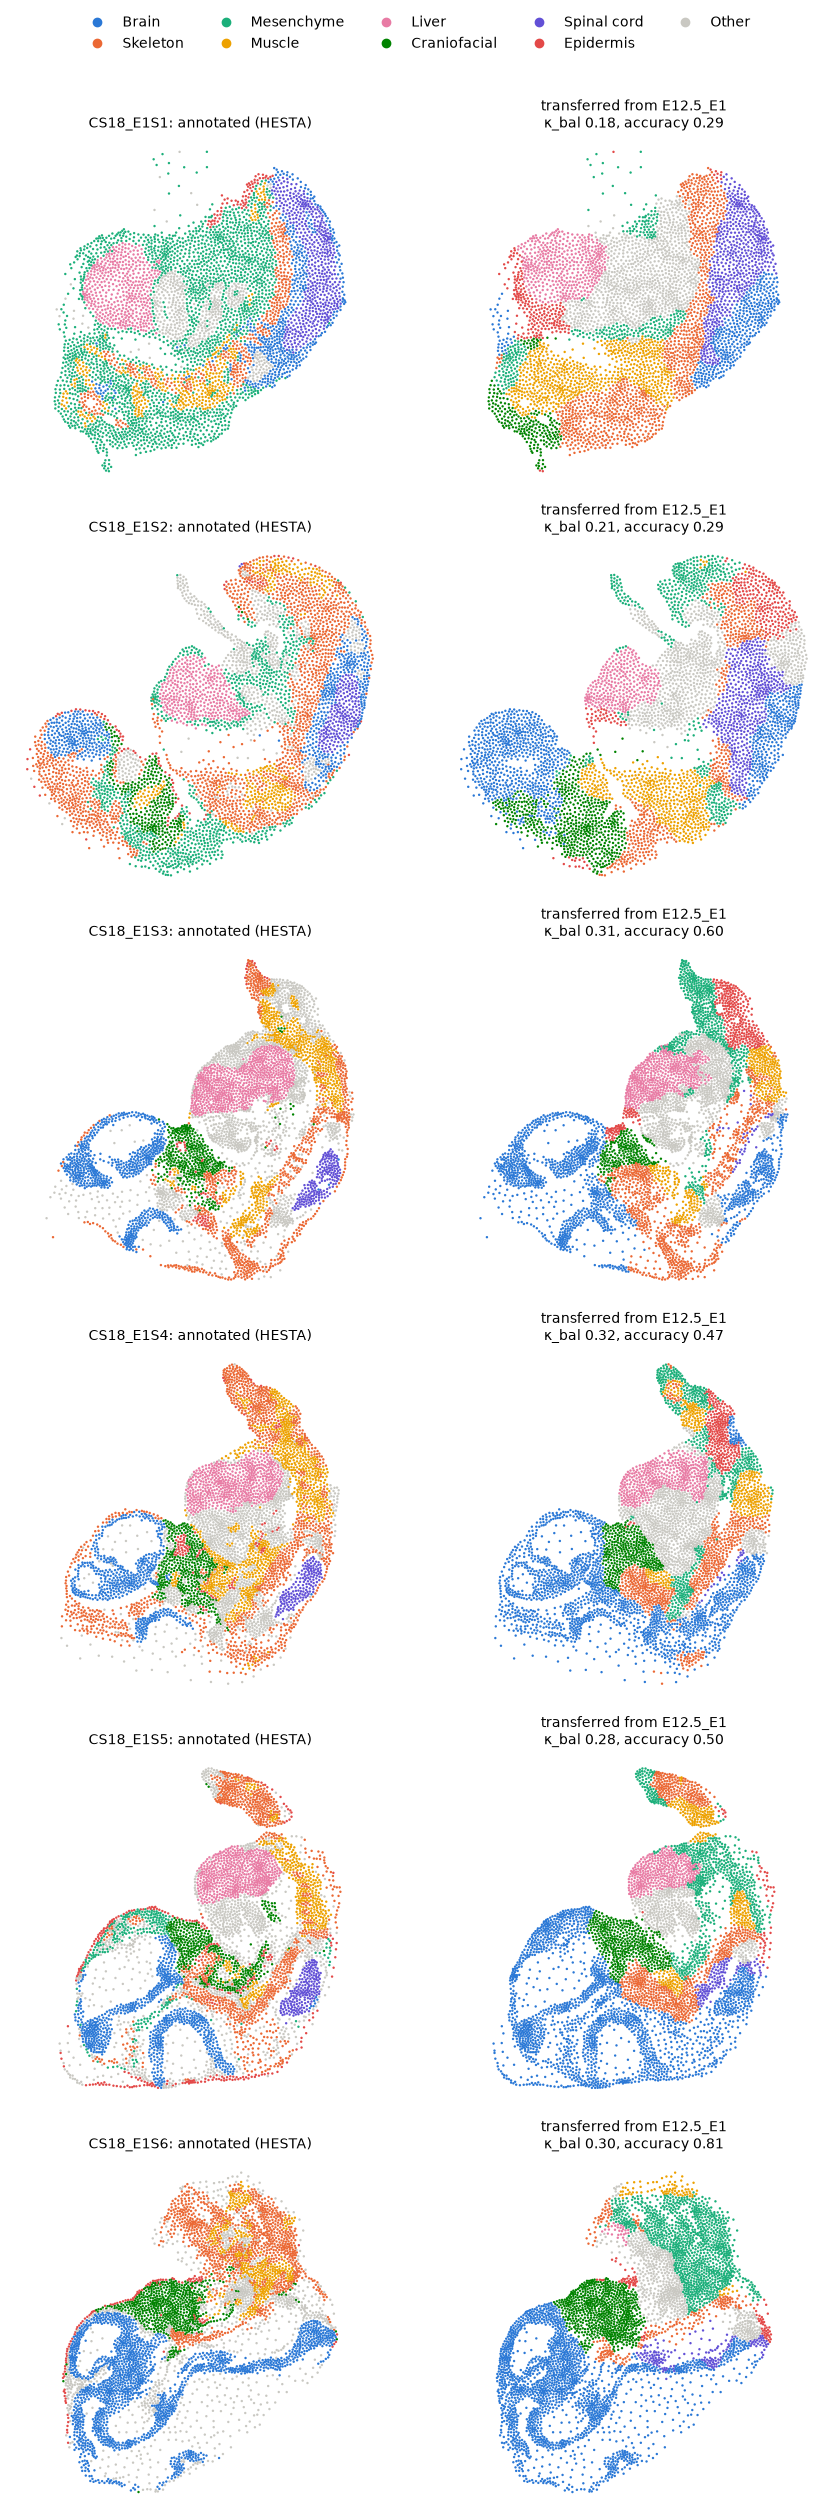

In [8]:
UNMATCHED = "#4d4d4d"
colors = lambda labels: [UNMATCHED if l == "unmatched" else pal.get(l, OTHER) for l in labels]
n = len(transfer)
fig, axes = plt.subplots(n, 2, figsize=(9, 4.2 * n), squeeze=False)
for (name, d), (ax_t, ax_p), r in zip(transfer.items(), axes, rows):
    for ax, labels, title in ((ax_t, d["true"], f"{name}: annotated (HESTA)"),
                              (ax_p, d["pred"], f"transferred from {emb_b.name}\n"
                                                f"κ_bal {r['kappa_bal']:.2f}, accuracy {r['acc_hard']:.2f}")):
        ax.scatter(*d["xy"].T, s=3, c=colors(labels), linewidths=0)
        ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title, fontsize=10)
handles = [Line2D([], [], marker="o", ls="", color=c, label=o) for o, c in pal.items()]
handles.append(Line2D([], [], marker="o", ls="", color=OTHER, label="Other"))
if any((d["pred"] == "unmatched").any() for d in transfer.values()):
    handles.append(Line2D([], [], marker="o", ls="", color=UNMATCHED, label="unmatched"))
fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 1 - 0.8 / fig.get_figheight()))
plt.show()

## Scores per section

κ_bal is 0 at chance and 1 when every organ's tissue goes to the same organ in the other embryo (§2a of the doc). `matched` is the mean share of a spot's mass that the unbalanced solve transports, and `unmatched_spots` the share of spots drawn as unmatched above. The benchmark reports the mean over both directions; this notebook shows the human queries only.

In [9]:
print(scores.round(3).to_string(index=False))
print(f"\nmean over the human sections: kappa_bal {scores.kappa_bal.mean():.3f}, accuracy {scores.acc_hard.mean():.3f}")

  section     L  kappa_bal   oms  acc_hard  matched  unmatched_spots
CS18_E1S1 0.326      0.178 0.260     0.290    0.525              0.0
CS18_E1S2 0.560      0.208 0.274     0.286    0.533              0.0
CS18_E1S3 0.574      0.314 0.383     0.601    0.509              0.0
CS18_E1S4 0.574      0.323 0.391     0.474    0.511              0.0
CS18_E1S5 0.574      0.280 0.352     0.499    0.551              0.0
CS18_E1S6 0.667      0.299 0.416     0.813    0.595              0.0

mean over the human sections: kappa_bal 0.267, accuracy 0.494
